

RASTER INFORMATION
Width (pixels): 1597
Height (pixels): 2212
Pixel size X: 0.0321 m
Pixel size Y: 0.0321 m
Raster width: 51.31 m
Raster height: 71.07 m

Bounds:
BoundingBox(left=354197.48284, bottom=5789628.588920001, right=354248.79445, top=5789699.660480001)


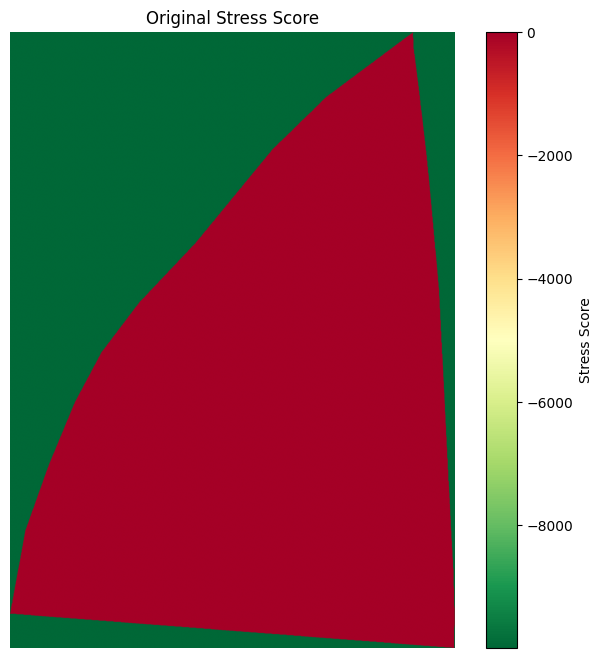

In [1]:
##########################################################################
# IMPORTS
##########################################################################

from pathlib import Path

import numpy as np
import rasterio

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

##########################################################################
# INPUT FILE
##########################################################################

RASTER_PATH = (Path("..")    / "stress_level"    / "2026"    / "flight_2026_04_22"    / "2026_04_22_stress_score.tif")

##########################################################################
# READ RASTER INFO
##########################################################################

with rasterio.open(RASTER_PATH) as src:

    data = src.read(1)

    transform = src.transform

    bounds = src.bounds

    pixel_width = src.res[0]
    pixel_height = src.res[1]

    width = src.width
    height = src.height

##########################################################################
# PRINT INFO
##########################################################################

print("\n")
print("=" * 60)
print("RASTER INFORMATION")
print("=" * 60)

print(
    f"Width (pixels): {width}"
)

print(
    f"Height (pixels): {height}"
)

print(
    f"Pixel size X: {pixel_width:.4f} m"
)

print(
    f"Pixel size Y: {pixel_height:.4f} m"
)

print(
    f"Raster width: {width * pixel_width:.2f} m"
)

print(
    f"Raster height: {height * pixel_height:.2f} m"
)

print("\nBounds:")

print(bounds)

print("=" * 60)

##########################################################################
# SHOW RASTER
##########################################################################

plt.figure(
    figsize=(8, 8)
)

plt.imshow(
    data,
    cmap="RdYlGn_r"
)

plt.title(
    "Original Stress Score"
)

plt.colorbar(
    label="Stress Score"
)

plt.axis("off")

plt.show()

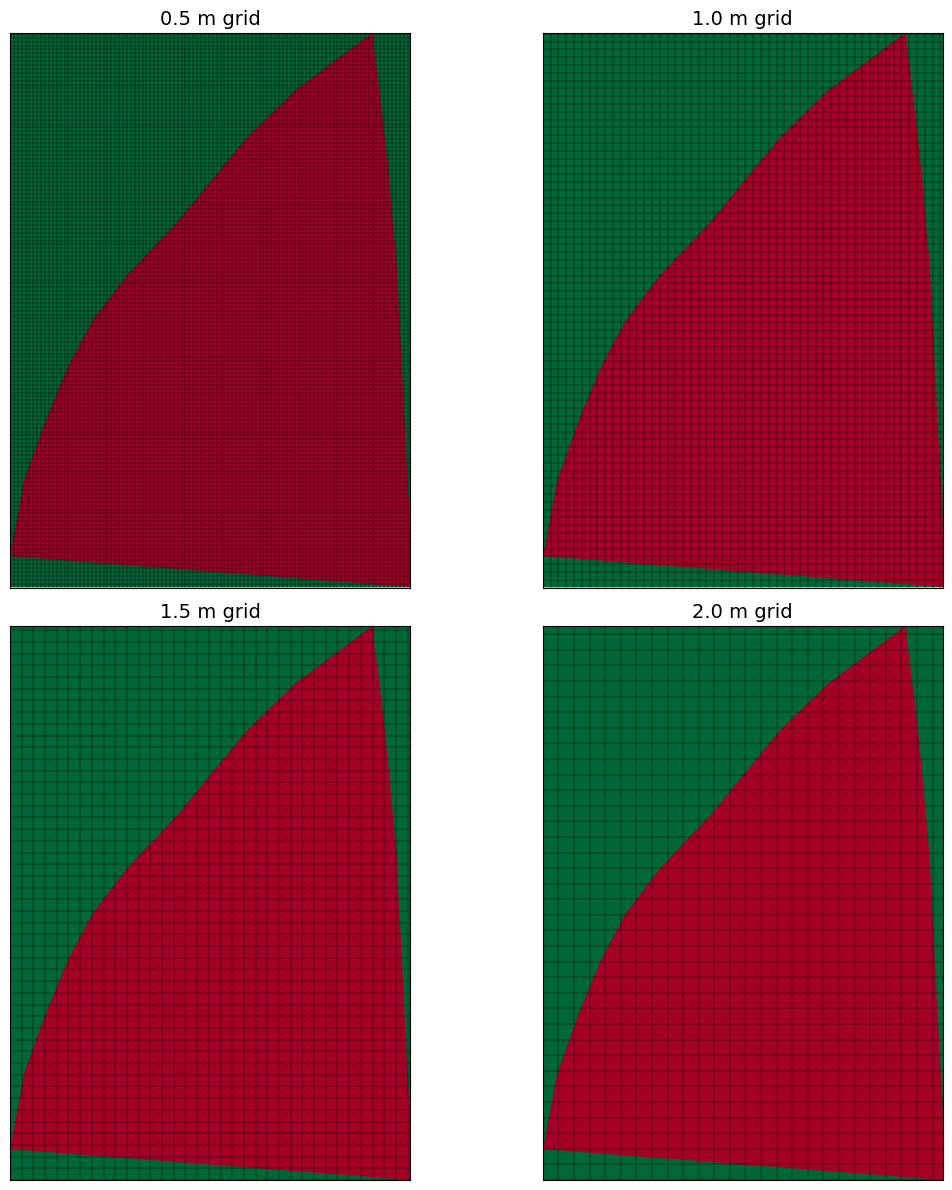

In [2]:
##########################################################################
# GRID COMPARISON
##########################################################################

GRID_SIZES = [
    0.5,
    1.0,
    1.5,
    2.0
]

##########################################################################
# PLOT
##########################################################################

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 12)
)

axes = axes.flatten()

extent = [

    bounds.left,
    bounds.right,

    bounds.bottom,
    bounds.top

]

for ax, grid_size in zip(
    axes,
    GRID_SIZES
):

    # --------------------------------------------------
    # SHOW STRESS MAP
    # --------------------------------------------------

    ax.imshow(

        data,

        cmap="RdYlGn_r",

        extent=extent,

        origin="upper"

    )

    # --------------------------------------------------
    # VERTICAL GRID
    # --------------------------------------------------

    x = np.arange(

        bounds.left,

        bounds.right,

        grid_size

    )

    for xx in x:

        ax.axvline(

            xx,

            color="black",

            linewidth=0.3

        )

    # --------------------------------------------------
    # HORIZONTAL GRID
    # --------------------------------------------------

    y = np.arange(

        bounds.bottom,

        bounds.top,

        grid_size

    )

    for yy in y:

        ax.axhline(

            yy,

            color="black",

            linewidth=0.3

        )

    ax.set_title(

        f"{grid_size} m grid",

        fontsize=14

    )

    ax.set_xticks([])
    ax.set_yticks([])

##########################################################################
# SAVE
##########################################################################

plt.tight_layout()

OUTPUT_DIR = Path("..")

plt.savefig(
    OUTPUT_DIR / "grid_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    OUTPUT_DIR / "grid_comparison.pdf",
    bbox_inches="tight"
)

plt.show()